100%|██████████| 9.91M/9.91M [00:00<00:00, 40.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.14MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.8MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.2MB/s]


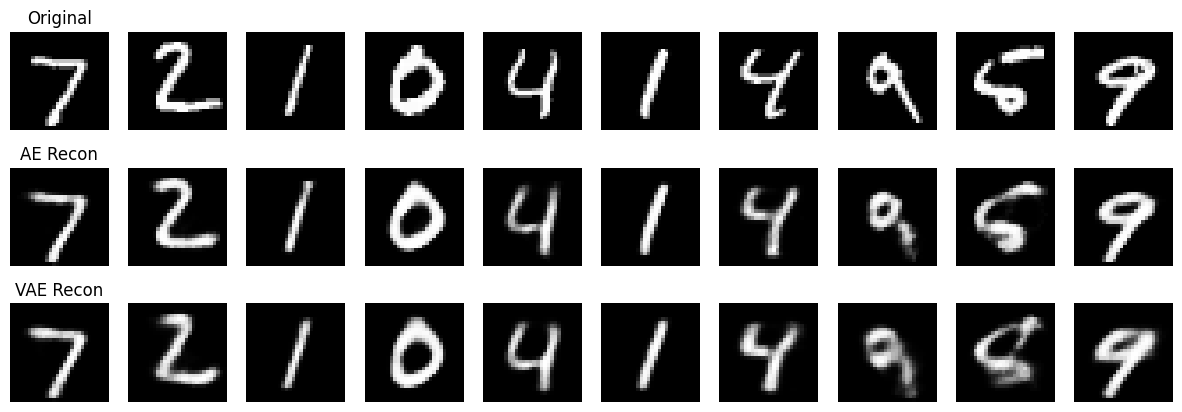

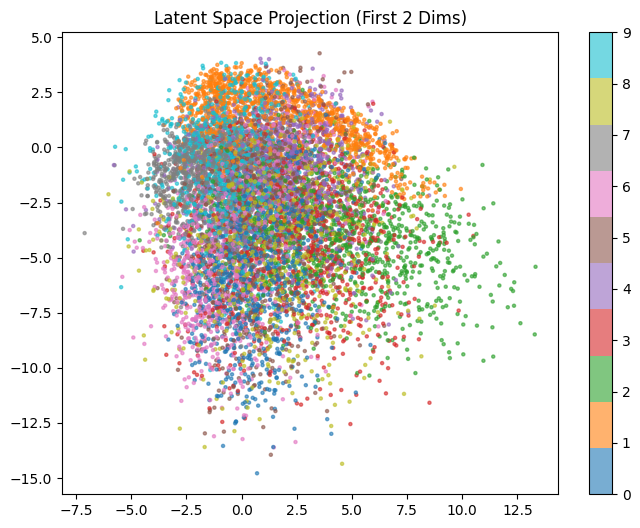

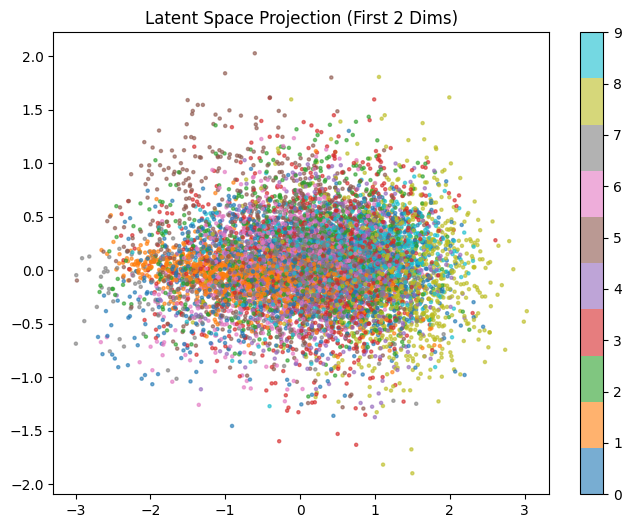

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=128, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=128, shuffle=False)

class Autoencoder(nn.Module):
    def __init__(self, latent_dim=20):
        super(Autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        z = self.encoder(x)
        x_recon = self.decoder(z)
        return x_recon.view(-1, 1, 28, 28), z

class VAE(nn.Module):
    def __init__(self, latent_dim=20):
        super(VAE, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc31 = nn.Linear(128, latent_dim)
        self.fc32 = nn.Linear(128, latent_dim)

        self.fc4 = nn.Linear(latent_dim, 128)
        self.fc5 = nn.Linear(128, 256)
        self.fc6 = nn.Linear(256, 28 * 28)

    def encode(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        return self.fc31(h2), self.fc32(h2)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h3 = F.relu(self.fc4(z))
        h4 = F.relu(self.fc5(h3))
        return torch.sigmoid(self.fc6(h4))

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_recon = self.decode(z)
        return x_recon.view(-1, 1, 28, 28), mu, logvar, z

def vae_loss(recon_x, x, mu, logvar):
    BCE = F.binary_cross_entropy(recon_x.view(-1, 28 * 28), x.view(-1, 28 * 28), reduction='sum')
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return BCE + KLD

def train_ae(model, epochs=10):
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()

    for epoch in range(epochs):
        model.train()
        for data, _ in train_loader:
            data = data.to(device)
            optimizer.zero_grad()
            recon, _ = model(data)
            loss = criterion(recon, data)
            loss.backward()
            optimizer.step()

def train_vae(model, epochs=10):
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    for epoch in range(epochs):
        model.train()
        for data, _ in train_loader:
            data = data.to(device)
            optimizer.zero_grad()
            recon_batch, mu, logvar, _ = model(data)
            loss = vae_loss(recon_batch, data, mu, logvar)
            loss.backward()
            optimizer.step()

def visualize_reconstructions(ae_model, vae_model, test_loader):
    ae_model.eval()
    vae_model.eval()
    dataiter = iter(test_loader)
    images, _ = next(dataiter)
    images = images.to(device)

    with torch.no_grad():
        ae_recon, _ = ae_model(images)
        vae_recon, _, _, _ = vae_model(images)

    images = images.cpu().numpy()
    ae_recon = ae_recon.cpu().numpy()
    vae_recon = vae_recon.cpu().numpy()

    fig, axes = plt.subplots(3, 10, figsize=(15, 5))
    for i in range(10):
        axes[0, i].imshow(np.squeeze(images[i]), cmap='gray')
        axes[0, i].axis('off')
        axes[1, i].imshow(np.squeeze(ae_recon[i]), cmap='gray')
        axes[1, i].axis('off')
        axes[2, i].imshow(np.squeeze(vae_recon[i]), cmap='gray')
        axes[2, i].axis('off')

    axes[0, 0].set_title('Original')
    axes[1, 0].set_title('AE Recon')
    axes[2, 0].set_title('VAE Recon')
    plt.show()

def visualize_latent_space(model, is_vae=False):
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for data, target in test_loader:
            data = data.to(device)
            if is_vae:
                mu, _ = model.encode(data.view(-1, 28 * 28))
                z = mu[:, :2]
            else:
                z = model.encoder(data.view(-1, 28 * 28))[:, :2]
            latents.append(z.cpu().numpy())
            labels.append(target.numpy())

    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(latents[:, 0], latents[:, 1], c=labels, cmap='tab10', alpha=0.6, s=5)
    plt.colorbar(scatter)
    plt.title('Latent Space Projection (First 2 Dims)')
    plt.show()

if __name__ == "__main__":
    ae = Autoencoder(latent_dim=20)
    train_ae(ae, epochs=10)

    vae = VAE(latent_dim=20)
    train_vae(vae, epochs=10)

    visualize_reconstructions(ae, vae, test_loader)
    visualize_latent_space(ae, is_vae=False)
    visualize_latent_space(vae, is_vae=True)